# 04 — Bootstrap: intervalos de confiança sem fórmulas

> **stats-foundations · Fase 1** — estimar a incerteza de *qualquer* métrica por reamostragem.

No [notebook 02](02-intervalos-confianca-teste-hipotese.ipynb) calculei intervalos de confiança com
fórmulas — que existem para proporções e médias, mas **não** para métricas mais complexas do dia a dia
de tráfego: **ticket mediano** (receita é log-normal), **ROAS**, **taxa de retenção**, razões em geral.

O **bootstrap** resolve isso com uma ideia simples e poderosa: se a minha amostra representa a
população, então **reamostrar com reposição** dela milhares de vezes simula "rodar a campanha de novo"
muitas vezes. A variação entre essas reamostragens é a incerteza da métrica — sem precisar de fórmula.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

RNG = np.random.default_rng(42)
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})
B = 10_000   # número de reamostragens bootstrap

def bootstrap(dados, estatistica, n_boot=B):
    # reamostra COM reposição n_boot vezes e aplica a estatística em cada reamostra
    n = len(dados)
    idx = RNG.integers(0, n, size=(n_boot, n))
    return estatistica(dados[idx], axis=1)

print("ok")

ok


## A. Sanidade: bootstrap bate com a fórmula (taxa de conversão)

Antes de usar o bootstrap onde não há fórmula, confirmo que ele concorda com a fórmula onde ela
existe — a taxa de conversão (proporção).

In [2]:
# 800 leads, conversão ~11%
dados = RNG.binomial(1, 0.11, 800)
taxa = dados.mean()

boot_taxa = bootstrap(dados, np.mean)
ci_boot = np.percentile(boot_taxa, [2.5, 97.5])

# fórmula (Wald) para comparar
se = np.sqrt(taxa * (1 - taxa) / len(dados))
ci_formula = (taxa - 1.96 * se, taxa + 1.96 * se)

print(f"Taxa observada: {taxa:.2%}")
print(f"IC 95% bootstrap: [{ci_boot[0]:.2%}, {ci_boot[1]:.2%}]")
print(f"IC 95% fórmula  : [{ci_formula[0]:.2%}, {ci_formula[1]:.2%}]")
print("=> praticamente idênticos: o bootstrap funciona.")

Taxa observada: 10.50%
IC 95% bootstrap: [8.50%, 12.62%]
IC 95% fórmula  : [8.38%, 12.62%]
=> praticamente idênticos: o bootstrap funciona.


## B. Onde brilha: IC do **ticket mediano** (receita log-normal)

Receita por cliente é assimétrica (log-normal, lembra do notebook 01). A **mediana** descreve o cliente
típico melhor que a média — mas não tem fórmula de IC fácil. O bootstrap resolve direto.

Ticket MEDIANO: R$ 468   IC 95% bootstrap: [R$ 439, R$ 502]
Ticket MÉDIO  : R$ 574  (puxado pela cauda; menos representativo do cliente típico)


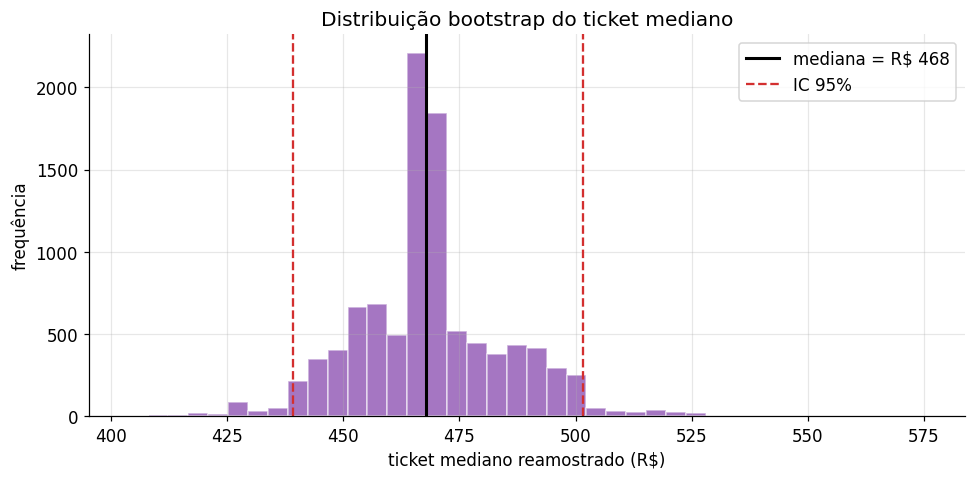

In [3]:
# receita de 300 clientes pagantes (log-normal: mediana ~ R$ 450)
receita = RNG.lognormal(mean=np.log(450), sigma=0.6, size=300)
mediana = np.median(receita)
media = receita.mean()

boot_med = bootstrap(receita, np.median)
ci_med = np.percentile(boot_med, [2.5, 97.5])

print(f"Ticket MEDIANO: R$ {mediana:,.0f}   IC 95% bootstrap: [R$ {ci_med[0]:,.0f}, R$ {ci_med[1]:,.0f}]")
print(f"Ticket MÉDIO  : R$ {media:,.0f}  (puxado pela cauda; menos representativo do cliente típico)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(boot_med, bins=40, color="#6a1b9a", alpha=0.6, edgecolor="white")
ax.axvline(mediana, color="black", lw=2, label=f"mediana = R$ {mediana:,.0f}")
ax.axvline(ci_med[0], color="#d32f2f", ls="--", lw=1.5, label="IC 95%")
ax.axvline(ci_med[1], color="#d32f2f", ls="--", lw=1.5)
ax.set_title("Distribuição bootstrap do ticket mediano")
ax.set_xlabel("ticket mediano reamostrado (R$)"); ax.set_ylabel("frequência")
ax.legend()
fig.tight_layout(); plt.show()

## C. Bootstrap da **diferença** A/B (sem assumir distribuição)

Posso reamostrar cada grupo e olhar a distribuição da diferença. Se o IC 95% da diferença **não cruza
o zero**, a diferença é significativa — mesma conclusão dos testes do notebook 03, por outro caminho.

Diferença observada B-A: +1.6%
IC 95% bootstrap da diferença: [-2.4%, +5.6%]
cruza zero? SIM (não significativo)


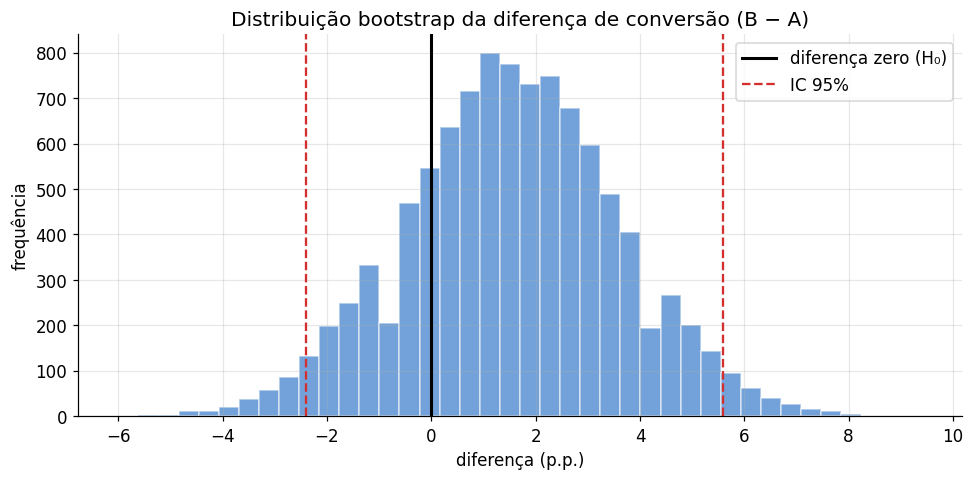

In [4]:
grupo_A = RNG.binomial(1, 0.10, 500)   # controle ~10%
grupo_B = RNG.binomial(1, 0.13, 500)   # teste ~13%
dif_obs = grupo_B.mean() - grupo_A.mean()

boot_A = bootstrap(grupo_A, np.mean)
boot_B = bootstrap(grupo_B, np.mean)
boot_dif = boot_B - boot_A
ci_dif = np.percentile(boot_dif, [2.5, 97.5])

print(f"Diferença observada B-A: {dif_obs:+.1%}")
print(f"IC 95% bootstrap da diferença: [{ci_dif[0]:+.1%}, {ci_dif[1]:+.1%}]")
print("cruza zero?", "SIM (não significativo)" if ci_dif[0] <= 0 <= ci_dif[1]
      else "NÃO (significativo)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(boot_dif * 100, bins=40, color="#1565c0", alpha=0.6, edgecolor="white")
ax.axvline(0, color="black", lw=2, label="diferença zero (H₀)")
ax.axvline(ci_dif[0] * 100, color="#d32f2f", ls="--", lw=1.5, label="IC 95%")
ax.axvline(ci_dif[1] * 100, color="#d32f2f", ls="--", lw=1.5)
ax.set_title("Distribuição bootstrap da diferença de conversão (B − A)")
ax.set_xlabel("diferença (p.p.)"); ax.set_ylabel("frequência")
ax.legend()
fig.tight_layout(); plt.show()

## Resumo — quando usar bootstrap

| Use bootstrap quando... | Exemplo de tráfego |
|---|---|
| não há fórmula fácil de IC | ticket **mediano**, ROAS, LTV, taxa de retenção |
| a distribuição é torta | receita (log-normal), tempo até conversão |
| a métrica é uma **razão** ou combinação | CPA, ROAS, receita por clique |
| quero IC da **diferença** sem assumir normalidade | comparação A/B de qualquer métrica |

**Receita de bolo:** (1) reamostrar com reposição ~10.000 vezes; (2) calcular a métrica em cada
reamostra; (3) IC 95% = percentis 2,5% e 97,5% da distribuição bootstrap.

**Próximo (notebook 05):** correlação e regressão — relação entre gasto e resultado, e por que
**correlação não é causação** (a ponte para a inferência causal da Fase 3).